# 01 · Explore the raw data

**Goal:** look at the raw data *before* changing anything, so we know what we are dealing with.

We will answer five simple questions:
1. How big is the data and what time range does it cover?
2. Are there gaps or missing values?
3. What does each signal look like over time?
4. Do the calibration files show that the sensors are off?
5. What will we need to fix in the next notebook (`02_clean`)?

> **How to use this notebook:** click a code cell and press **Shift + Enter** to run it.
> Run the cells from top to bottom. Nothing here changes your raw data.

## 1. Set up
This loads the tools we need and our own loading code from `src/load.py`.

In [1]:
import sys
sys.path.insert(0, "../src")   # lets the notebook import our code from the src folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from load import load_main, load_flow_calibration, load_manual_tp

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = "../figures/"


## 2. Load the three files
`df` is the main 30-second time series. `cal` is the flow-meter calibration. `manual` is the hand-measured temperature and pressure.

In [2]:
df = load_main()
cal = load_flow_calibration()
manual = load_manual_tp()

print("Main data  :", df.shape, "(rows, columns)")
print("Calibration:", cal.shape)
print("Manual T&P :", manual.shape)
df.head()

Main data  : (81239, 10) (rows, columns)
Calibration: (8, 6)
Manual T&P : (75, 5)


,p16B_psi,q16B_1_gpm,q16B_2_gpm,T16B_F,sep1_gpm,sep2_gpm,sep_total_gpm,p16A_psi,liberty_bpm,liberty_p_psi
time,,,,,,,,,,
2024-08-08 07:00:00,NaN,0.11,NaN,71.78,NaN,NaN,NaN,NaN,NaN,NaN
2024-08-08 07:00:30,NaN,0.11,NaN,71.78,NaN,NaN,NaN,NaN,NaN,NaN
2024-08-08 07:01:00,NaN,0.11,NaN,71.78,NaN,NaN,NaN,NaN,NaN,NaN
2024-08-08 07:01:30,NaN,0.11,NaN,71.78,NaN,NaN,NaN,NaN,NaN,NaN
2024-08-08 07:02:00,NaN,0.11,NaN,71.78,NaN,NaN,NaN,NaN,NaN,NaN


**Column meanings** (from the dataset's Read Me):

| Column | Meaning | Unit |
|---|---|---|
| `p16A_psi`, `liberty_p_psi` | Pressure at the injection well (two sensors) | psi |
| `liberty_bpm` | Injection rate (pump truck) | barrels/min |
| `p16B_psi` | Pressure at the producing well | psi |
| `q16B_1_gpm`, `q16B_2_gpm` | Producer flow meters (before the separator) | gallons/min |
| `sep1_gpm`, `sep2_gpm`, `sep_total_gpm` | Flow leaving the separator | gallons/min |
| `T16B_F` | Producer fluid temperature | °F |

## 3. Time range and sampling
The data should be one row every 30 seconds with no holes.

In [3]:
step = df.index.to_series().diff().dt.total_seconds()
print("Start :", df.index.min())
print("End   :", df.index.max())
print("Length:", (df.index.max() - df.index.min()).round("h"))
print("\nTime between rows (seconds):")
print(step.value_counts().head())
print("\nDuplicate timestamps:", df.index.duplicated().sum())

Start : 2024-08-08 07:00:00
End   : 2024-09-05 11:59:40
Length: 28 days 05:00:00

Time between rows (seconds):
time
30.0    81237
70.0        1
Name: count, dtype: int64

Duplicate timestamps: 0


**Reading this:** almost every step is exactly 30 s, so the time axis is clean. The one 70 s step is harmless.

## 4. Missing data
Sensors drop out. Let's see how much is missing and **when**.

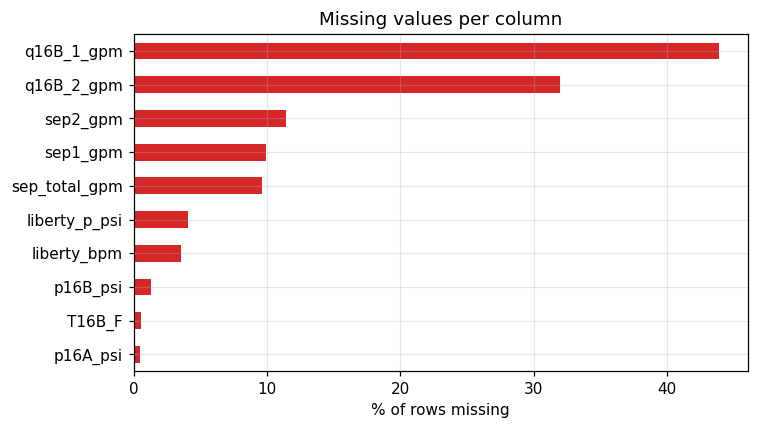

p16A_psi          0.4
T16B_F            0.5
p16B_psi          1.3
liberty_bpm       3.6
liberty_p_psi     4.1
sep_total_gpm     9.6
sep1_gpm          9.9
sep2_gpm         11.4
q16B_2_gpm       32.0
q16B_1_gpm       43.9
dtype: float64

In [4]:
missing_pct = df.isna().mean().mul(100).sort_values()
ax = missing_pct.plot.barh(color="tab:red", figsize=(7, 4))
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per column")
plt.tight_layout(); plt.savefig(FIG_DIR + "01_missing_per_column.png"); plt.show()
missing_pct.round(1)

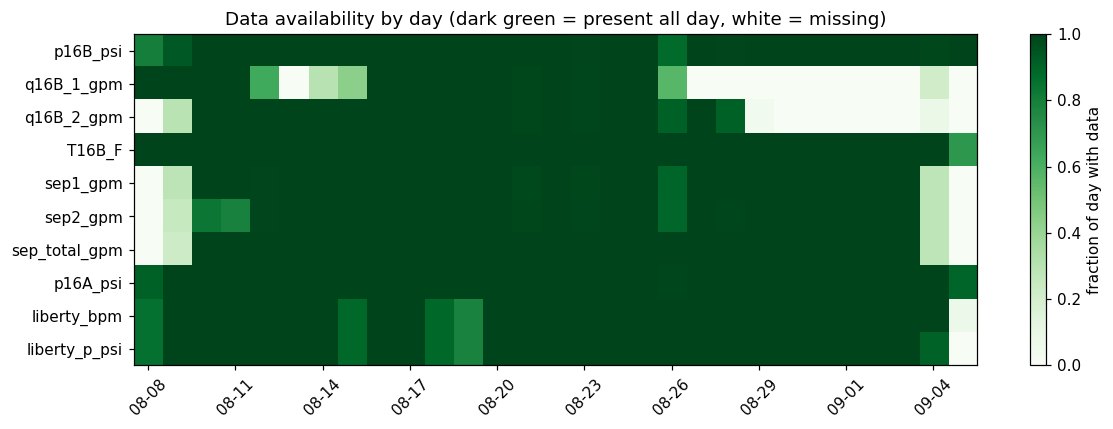

In [5]:
# When is each signal present? Share of rows with data, per day.
avail = df.notna().groupby(df.index.date).mean().T
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(avail.values, aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set_yticks(range(len(avail.index))); ax.set_yticklabels(avail.index)
ax.set_xticks(range(0, avail.shape[1], 3))
ax.set_xticklabels([str(d)[5:] for d in avail.columns[::3]], rotation=45)
ax.set_title("Data availability by day (dark green = present all day, white = missing)")
ax.grid(False); plt.colorbar(im, label="fraction of day with data")
plt.tight_layout(); plt.savefig(FIG_DIR + "01_availability_by_day.png"); plt.show()

**Reading this:** several signals only start after the test began, and some stop before the end. Producer flow meter 1 (`q16B_1_gpm`) has the most holes, which matches the report calling it the *suspect* meter.

## 5. Summary statistics
Look at `min` and `max` for anything impossible or suspicious.

In [6]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
p16B_psi,80203.0,295.0,275.2,0.2,236.5,252.1,266.5,1592.9
q16B_1_gpm,45583.0,244.2,156.5,0.0,0.2,321.0,336.1,661.3
q16B_2_gpm,55275.0,322.4,39.5,0.3,313.3,331.1,341.5,701.8
T16B_F,80805.0,323.5,80.2,54.1,326.6,356.0,362.1,367.0
sep1_gpm,73183.0,152.8,29.6,0.9,140.1,155.7,176.9,601.3
sep2_gpm,71973.0,171.6,33.9,0.1,170.8,179.6,190.8,600.7
sep_total_gpm,73431.0,320.1,69.8,0.0,312.5,331.5,369.9,799.2
p16A_psi,80876.0,2594.5,680.3,0.6,2785.2,2845.2,2897.8,3057.1
liberty_bpm,78323.0,9.0,2.6,0.0,10.0,10.0,10.1,13.5
liberty_p_psi,77944.0,2646.0,687.5,0.0,2818.6,2885.1,2944.5,3046.1


**Reading this:** `p16B_psi` has a median near 252 psi but a maximum of 1,593 psi. That is a spike, not real. Temperatures as low as 54 °F are the pre-test, cold well, not an error.

## 6. The injection side (well 16A)
The pump truck pushes cold water down. Rate and pressure are the "input" of the experiment.

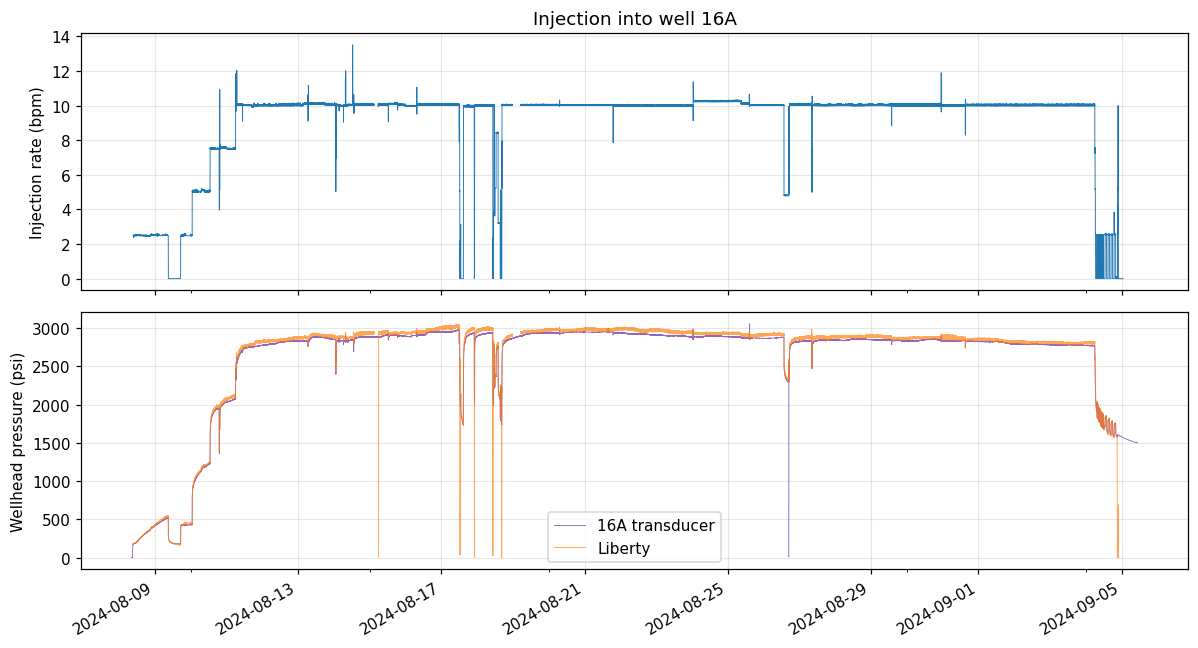

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
df["liberty_bpm"].plot(ax=ax[0], color="tab:blue", lw=0.6)
ax[0].set_ylabel("Injection rate (bpm)"); ax[0].set_title("Injection into well 16A")
df["p16A_psi"].plot(ax=ax[1], color="tab:purple", lw=0.6, label="16A transducer")
df["liberty_p_psi"].plot(ax=ax[1], color="tab:orange", lw=0.6, alpha=0.7, label="Liberty")
ax[1].set_ylabel("Wellhead pressure (psi)"); ax[1].legend(); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR + "01_injection_raw.png"); plt.show()

**Reading this:** you can see the **step-up** at the start (2.5 → 5 → 7.5 → 10 bpm) exactly as in the report's schedule, then a long steady plateau at about 10 bpm. Pressure follows the rate. The dips to zero around 17 to 18 Aug are pump stops, there is a period at about half rate on 26 Aug, and the rapid cycling at the very end is a deliberate injection-cycling experiment, not noise. We will label these phases in notebook 02.

## 7. The production side (well 16B)
Hot water comes back up. Flow, temperature and pressure are the "output".

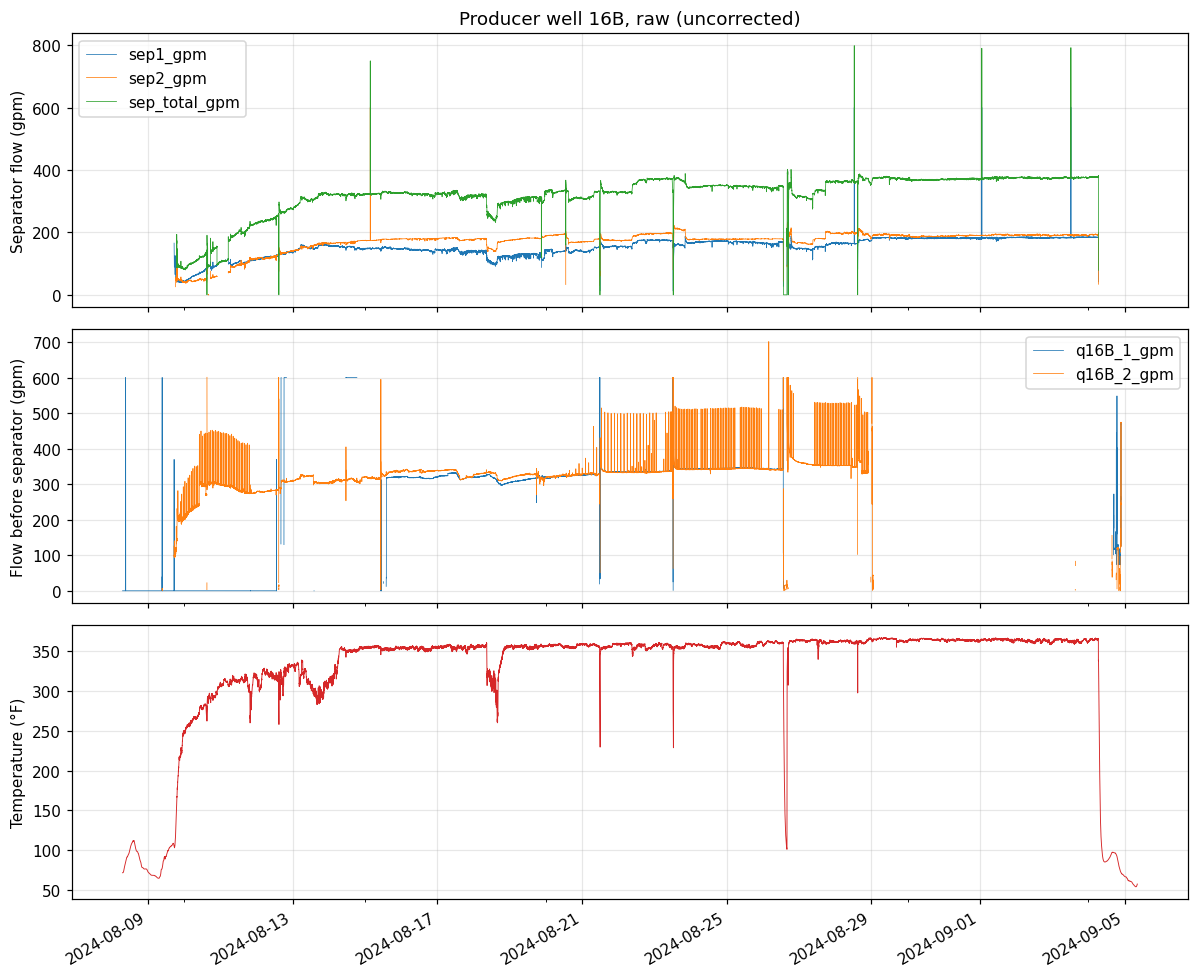

In [8]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
df[["sep1_gpm", "sep2_gpm", "sep_total_gpm"]].plot(ax=ax[0], lw=0.5)
ax[0].set_ylabel("Separator flow (gpm)"); ax[0].set_title("Producer well 16B, raw (uncorrected)")
df[["q16B_1_gpm", "q16B_2_gpm"]].plot(ax=ax[1], lw=0.5)
ax[1].set_ylabel("Flow before separator (gpm)")
df["T16B_F"].plot(ax=ax[2], color="tab:red", lw=0.6)
ax[2].set_ylabel("Temperature (°F)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR + "01_production_raw.png"); plt.show()

**Reading this:**
- **Temperature** is cold (50 to 110 °F) while the well is still shut in, then climbs over about 5 days as hot rock heats the water, and levels off near 355 to 365 °F. The sharp dips are brief interruptions.
- **Separator flow** (top) is the cleanest flow signal. It rises as the fracture network fills, then flattens. Short spikes to 800 gpm are glitches.
- **Flow before the separator** (middle) has violent oscillating bursts up to ~500 gpm. This is the impaired meter the report mentions, so we will **not** use it for the final numbers. The separator-outlet meters, corrected with the calibration, are the trusted source.

## 8. The pressure spikes on 16B

Rows above 600 psi: 3581 of 80203
Median: 252 psi


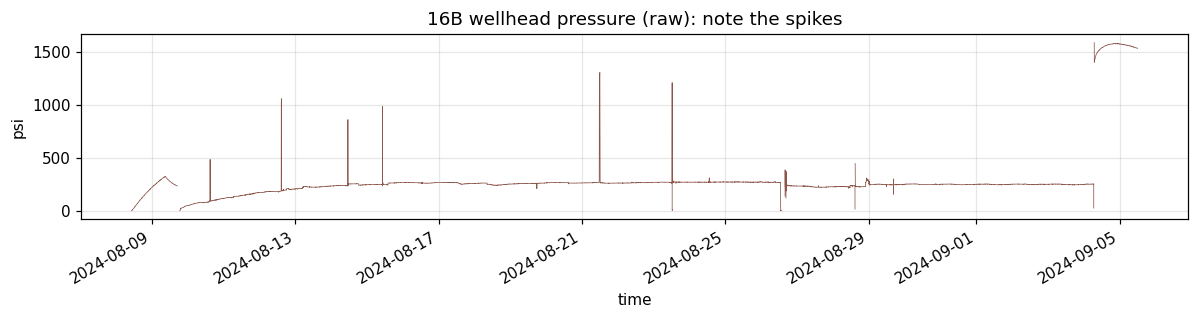

In [9]:
p = df["p16B_psi"]
print("Rows above 600 psi:", (p > 600).sum(), "of", p.notna().sum())
print("Median:", round(p.median()), "psi")
ax = p.plot(figsize=(11, 3), lw=0.5, color="tab:brown")
ax.set_title("16B wellhead pressure (raw): note the spikes"); ax.set_ylabel("psi")
plt.tight_layout(); plt.savefig(FIG_DIR + "01_p16B_spikes.png"); plt.show()

The report says this transducer "read erratically", so we will treat 16B pressure with caution, and use the manual gauge readings to check it.

## 9. Are the flow meters accurate?
The calibration file compares the **pump truck's true rate** (Liberty) with each flow meter. If the meters were perfect, the points would sit on the dashed line.

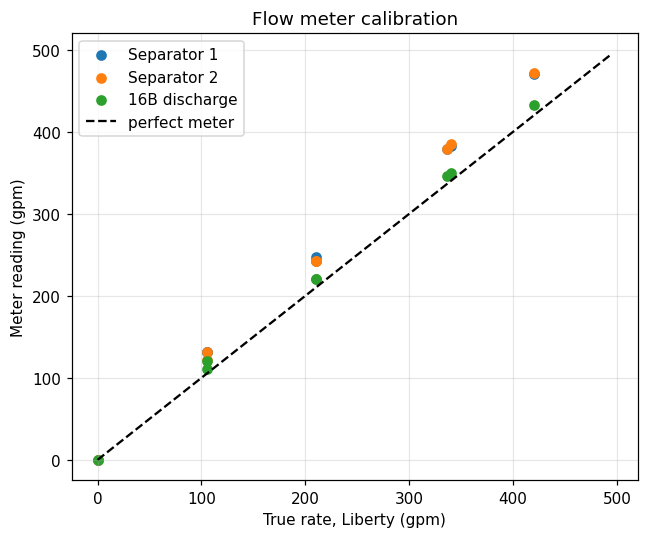

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
for col, label in [("sep1_raw_gpm", "Separator 1"), ("sep2_raw_gpm", "Separator 2"), ("dis16B_raw_gpm", "16B discharge")]:
    ax.scatter(cal["liberty_gpm"], cal[col], label=label)
lim = [0, cal[["sep1_raw_gpm", "sep2_raw_gpm"]].max().max() * 1.05]
ax.plot(lim, lim, "k--", label="perfect meter")
ax.set_xlabel("True rate, Liberty (gpm)"); ax.set_ylabel("Meter reading (gpm)")
ax.set_title("Flow meter calibration"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR + "01_flow_calibration.png"); plt.show()

**Reading this:** the separator meters sit *above* the dashed line, meaning they read **too high**, by roughly 10 to 12%. We will correct this in notebook 02.

## 10. Manual temperature and pressure checks

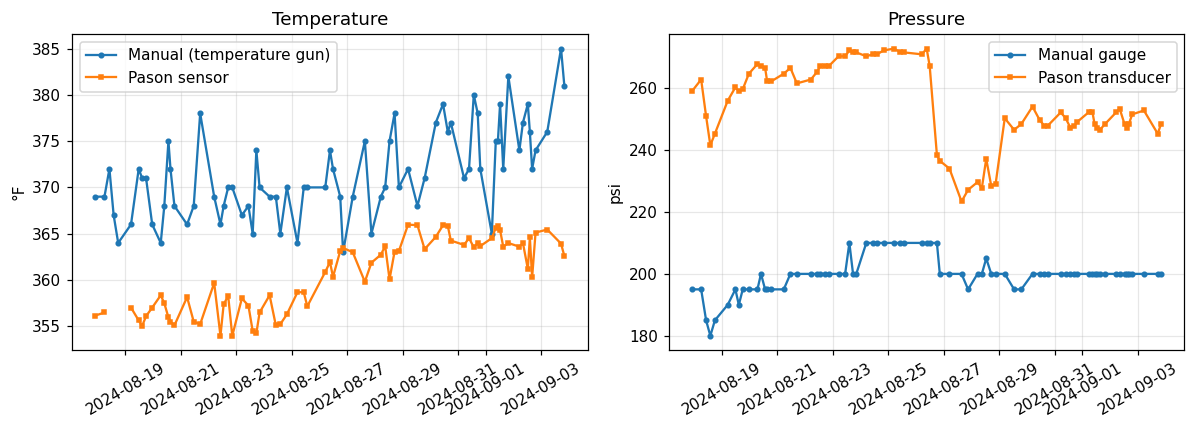

Average temperature difference (manual - Pason): 11.3 °F
Average pressure difference (manual - Pason)   : -55 psi


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(manual.index, manual["T_manual_F"], "o-", ms=3, label="Manual (temperature gun)")
ax[0].plot(manual.index, manual["T_pason_F"], "s-", ms=3, label="Pason sensor")
ax[0].set_ylabel("°F"); ax[0].set_title("Temperature"); ax[0].legend()
ax[1].plot(manual.index, manual["p_manual_psi"], "o-", ms=3, label="Manual gauge")
ax[1].plot(manual.index, manual["p_pason_psi"], "s-", ms=3, label="Pason transducer")
ax[1].set_ylabel("psi"); ax[1].set_title("Pressure"); ax[1].legend()
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG_DIR + "01_manual_checks.png"); plt.show()
print("Average temperature difference (manual - Pason):", round(manual["dT_F"].mean(), 1), "°F")
print("Average pressure difference (manual - Pason)   :", round((manual["p_manual_psi"] - manual["p_pason_psi"]).mean()), "psi")

**Reading this:** the Pason temperature reads about 11 °F low (the thermocouple did not reach the flowing fluid, as the report explains), and the Pason pressure reads about 55 psi high.

## 11. Summary: what we must fix in `02_clean`

| Problem | Evidence | Fix |
|---|---|---|
| Separator flow reads ~10% high | Calibration plot | Apply the fitted calibration to Liberty |
| Producer temperature reads ~11 °F low | Manual vs Pason | Add the measured offset |
| 16B pressure has spikes and reads high | Spike plot and manual check | Flag or remove spikes; treat as indicative only |
| Many missing values and zeros | Availability map | Flag test phases; only fill short gaps |
| Test has distinct phases | Injection plot | Label step-up, steady state and shut-in |

**Next:** open `02_clean.ipynb`.